# Lab 2 — MountainCar: Monte Carlo control vs Policy / Value Iteration

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../lab1_pi_vi")
import mountain_car_setup as lab1
from mc_mountaincar import *

GAMMA = 0.99          # same as in Lab 1
N_MC = 20             # MC grid: 20x20
N_DP = 200            # PI/VI grid from Lab 1: 200x200
N_EPISODES = 20_000
K = 100               # weight for height shaping
K_ENERGY = 50_000     # weight for energy shaping (energy values are ~200x smaller than height)

## 1. Settings and why

- **Grid 20×20** (400 states): MC must visit every (state, action) many times, and 40×40 still learned nothing after 30 000 episodes.
- **γ = 0.99**: same as in Lab 1, so the results are comparable.
- **Reward shaping by height**: rewards climbing either side of the valley, so the necessary roll back is not punished
- **k = 100**: height changes only ~0.001–0.01 per step, so ×100 brings the bonus to the scale of the −1 step reward.
- **Second variant: shaping by energy** `E = 0.0025·sin(3p)/3 + v²/2` (potential + kinetic): rolling freely keeps E constant, so only the engine's real contribution is rewarded.
- **k = 50 000 for energy**: energy values are ~200× smaller than height, so k must be larger for the same scale (k = 5 000 learned nothing).
- **ε = 1.0 at start**: the agent knows nothing yet, so it explores fully randomly.
- **ε decay 0.9995**: the agent keeps exploring a lot until it first reaches the flag
- **ε min 0.05**: a little exploration always remains, so rarely visited states keep getting updated.
- **α = 0.02**: small step averages many noisy episodes.
- **First-visit MC**: one update per (state, action) per episode
- **Fixed 20 000 episodes**

## 2. Training: height shaping, energy shaping, no shaping

In [2]:
mc = mc_control(N_MC, N_MC, N_EPISODES, GAMMA, k=K)
mc_energy = mc_control(N_MC, N_MC, N_EPISODES, GAMMA, k=K_ENERGY, reward_fn=energy_reward)
mc_noshape = mc_control(N_MC, N_MC, N_EPISODES, GAMMA, k=0)
print(f"MC height (k={K}): {mc['time']:.0f} s, {mc['env_steps']:,} env steps")
print(f"MC energy (k={K_ENERGY}): {mc_energy['time']:.0f} s, {mc_energy['env_steps']:,} env steps")
print(f"MC (k=0):   {mc_noshape['time']:.0f} s, {mc_noshape['env_steps']:,} env steps")

MC height (k=100): 39 s, 3,495,312 env steps
MC energy (k=50000): 37 s, 2,905,263 env steps
MC (k=0):   44 s, 4,000,000 env steps


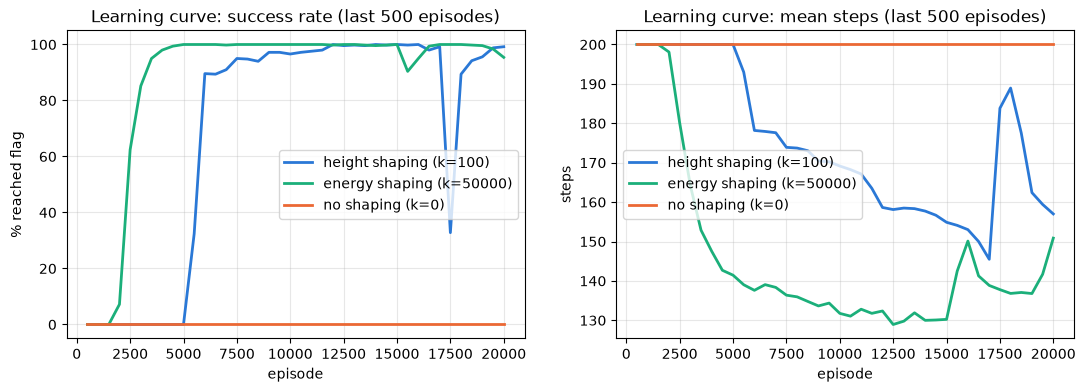

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for res, label, color in [(mc, f"height shaping (k={K})", "#2a78d6"), (mc_energy, f"energy shaping (k={K_ENERGY})", "#1baf7a"),
                           (mc_noshape, "no shaping (k=0)", "#eb6834")]:
    axes[0].plot(res["log"]["episode"], res["log"]["success_%"], label=label, color=color, lw=2)
    axes[1].plot(res["log"]["episode"], res["log"]["mean_steps"], label=label, color=color, lw=2)
axes[0].set(title="Learning curve: success rate (last 500 episodes)", xlabel="episode", ylabel="% reached flag")
axes[1].set(title="Learning curve: mean steps (last 500 episodes)", xlabel="episode", ylabel="steps")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.show()

- **Start**: ~0% success for thousands of episodes — the policy is random and 200 random steps almost never reach the flag.
- **With shaping**: the agent first learns to swing higher (climbing is rewarded), the higher swings eventually reach the flag, and from there the success rate jumps to ~90–100%.
- **Energy shaping learns faster** and needs fewer env steps: it never punishes the natural roll down, so the signal points only at useful pushes.
- **Without shaping**: flat 0%. Every episode gives exactly −200, all actions look equally bad → nothing to learn from (sparse reward).
- Occasional dips: with ε-greedy and a coarse grid, one bad update can break a part of the policy for a while; the small α lets it recover.
- Training success is measured *with* ε exploration, so it is slightly below the greedy test result.

## 3. PI / VI from Lab 1

In [4]:
P, R, done = lab1.build_model(N_DP, N_DP)
pi = lab1.policy_iteration(P, R, done, GAMMA)
vi = lab1.value_iteration(P, R, done, GAMMA)

# reference: VI on the same coarse 20x20 grid as MC
P20, R20, done20 = lab1.build_model(N_MC, N_MC)
vi20 = lab1.value_iteration(P20, R20, done20, GAMMA)

## 4. Testing and comparison (100 greedy episodes, seeds 0–99)

- PI/VI have the model (P, R): their env steps = one simulated step per (state, action) to build it. MC has no model: env steps = all played training episodes.
- Shaped reward: height shaping for PI, VI and MC height; energy shaping for MC energy.

In [5]:
tests = {
    "PI (200×200)":      (test_policy(pi["policy"], N_DP, N_DP, K), pi["time"], 3 * N_DP**2),
    "VI (200×200)":      (test_policy(vi["policy"], N_DP, N_DP, K), vi["time"], 3 * N_DP**2),
    "MC height (20×20)": (test_policy(mc["policy"], N_MC, N_MC, K), mc["time"], mc["env_steps"]),
    "MC energy (20×20)": (test_policy(mc_energy["policy"], N_MC, N_MC, K_ENERGY, energy_reward), mc_energy["time"], mc_energy["env_steps"]),
    "VI (20×20)":        (test_policy(vi20["policy"], N_MC, N_MC, K), vi20["time"], 3 * N_MC**2),
}
pd.DataFrame.from_dict({name: {
    "Env steps for learning": steps,
    "Training time, s": t,
    "Mean steps to flag": r["mean_steps"],
    "Success rate, %": r["success_%"],
    "Mean reward (original)": r["mean_reward"],
    "Mean reward (shaped)": float(r["mean_shaped_reward"]),
} for name, (r, t, steps) in tests.items()}, orient="index").round(2)

,Env steps for learning,"Training time, s",Mean steps to flag,"Success rate, %",Mean reward (original),Mean reward (shaped)
PI (200×200),120000,0.71,120.41,100.0,-120.41,-31.28
VI (200×200),120000,0.11,120.41,100.0,-120.41,-31.28
MC height (20×20),3495312,38.67,153.50,100.0,-153.50,-64.34
MC energy (20×20),2905263,37.00,146.74,100.0,-146.74,-7.64
VI (20×20),1200,0.01,NaN,0.0,-200.00,-182.50


## 5. Visualization

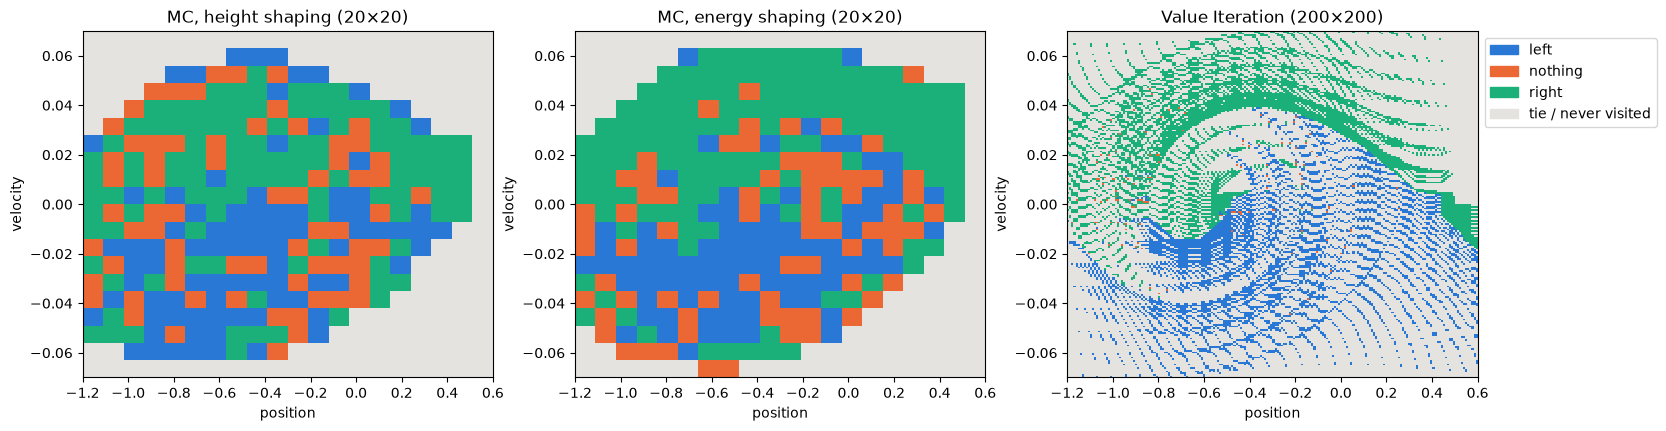

In [6]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

def without_ties(Q, policy):
    """Replace states where several actions are equally best with 3 (grey)."""
    ties = np.isclose(Q, Q.max(axis=1, keepdims=True)).sum(axis=1) > 1
    return np.where(ties, 3, policy)

colors = ["#2a78d6", "#eb6834", "#1baf7a", "#e4e3df"]
extent = [lab1.POS_MIN, lab1.POS_MAX, lab1.VEL_MIN, lab1.VEL_MAX]
panels = [("MC, height shaping (20×20)", without_ties(mc["Q"], mc["policy"]), N_MC),
          ("MC, energy shaping (20×20)", without_ties(mc_energy["Q"], mc_energy["policy"]), N_MC),
          ("Value Iteration (200×200)", without_ties(lab1.q_values(vi["V"], P, R, done, GAMMA), vi["policy"]), N_DP)]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (name, policy, n) in zip(axes, panels):
    ax.imshow(policy.reshape(n, n).T, origin="lower", aspect="auto", extent=extent,
              cmap=ListedColormap(colors), vmin=0, vmax=3, interpolation="nearest")
    ax.set(title=name, xlabel="position", ylabel="velocity")
axes[2].legend(handles=[Patch(color=c, label=l) for c, l in zip(colors, ["left", "nothing", "right", "tie / never visited"])],
               loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

- Grey: for MC = states **never visited** in training (all Q = 0); for VI = ties (several actions reach the flag in the same number of steps).
- All three show the same strategy: **right when moving right** (green, top), **left when moving left** (blue, bottom).
- MC only knows the states it played through: the oval of visited states = the range of swings it made. Energy MC visited a slightly wider area (faster swings).
- Energy MC has a more solid green band on top; both MC maps have "nothing" (orange) noise near velocity 0, where states are visited less and Q estimates are rough.
- VI covers every state, because it computed values from the model, not from experience.

MC, height shaping: 157 steps, reached flag: True


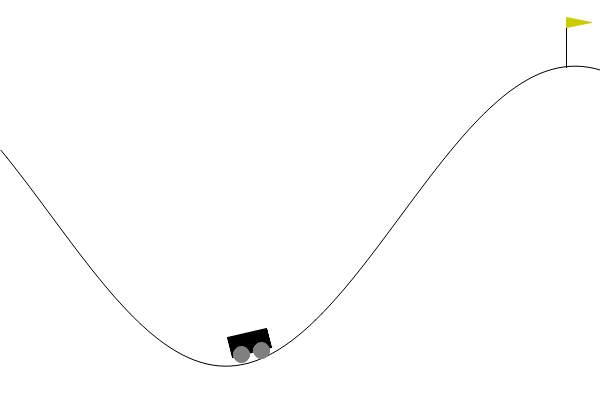

MC, energy shaping: 152 steps, reached flag: True


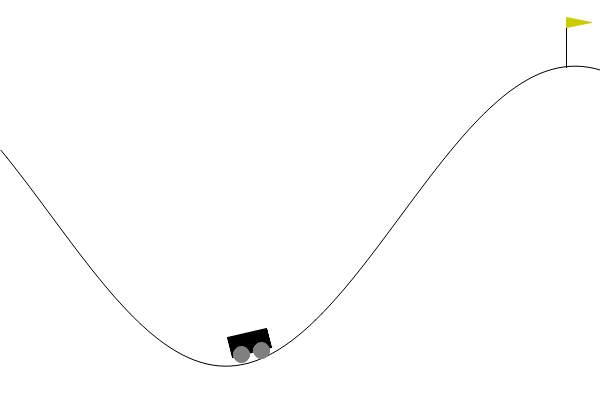

In [7]:
from PIL import Image as PILImage
from IPython.display import Image, display

for name, res in [("height", mc), ("energy", mc_energy)]:
    _, reached, traj, frames = lab1.run_episode(res["policy"], N_MC, N_MC, seed=42, render_mode="rgb_array")
    print(f"MC, {name} shaping: {len(traj) - 1} steps, reached flag: {reached}")
    gif = [PILImage.fromarray(f) for f in frames[::2]]
    path = f"mc_{name}_episode.gif"
    gif[0].save(path, save_all=True, append_images=gif[1:], duration=40, loop=0)
    display(Image(filename=path))

### Conclusion

**1. MC needs far more computation than PI/VI.**
- PI/VI read the exact model, so every update uses the true next state of *every* state at once → about a second.
- MC knows nothing about the physics: it must play 20 000 full episodes (~3–4 million env steps), and in the beginning it explores randomly, so most of the experience is wasted.
- Each MC estimate is an average of noisy returns from whole episodes, so it needs many visits per (state, action).

**2. Without reward shaping MC does not learn at all.**
- The original reward is **sparse**: −1 every step, and the only "good" event is reaching the flag.
- A random agent practically never reaches the flag in 200 steps → every return is the same −200 → Q gives no preference between actions.
- Height-based shaping gives a signal on *every* step: actions that make the swing higher are better, which leads the agent toward the flag.

**3. MC policy is good but not optimal.**
- MC reaches the flag (~95–100%), but in more steps (~150 vs ~120 for PI/VI).
- Energy shaping gets closer to the optimum than height shaping (fewer steps), because it rewards only pushes that add energy, which is exactly what the optimal policy does.
- Reasons for the remaining gap: the coarse 20×20 grid (one action for a large area of states), a limited number of episodes, and shaping, which optimizes a slightly different objective (climb high) than "reach the flag as fast as possible".
- Interesting: **VI on the same 20×20 grid fails** — its model is built from one step from the bin centre, which on a coarse grid lands in the same bin. MC does not have this problem: it learns from real transitions.